<a href="https://colab.research.google.com/github/markpy18/Atividade_Inteligencia_Artificial_02/blob/main/AtividadeIA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Índice

Navegue rapidamente pelas seções deste estudo estatístico utilizando os links abaixo:

* [Bibliotecas](#Bibliotecas)
* [Carregamento do dataset](#Carregamento-do-dataset)
* [A: Boxplots e média](#A:-Boxplots-e-médias)
* [B: Estimando um intervalo de confiança para a média](#B:-Estimando-um-intervalo-de-confiança-para-a-média)
* [C: P-value em um Teste de Hipótese](#C:-P-value-em-um-Teste-de-Hipótese)
* [D: Nivel de significância](#D:-Nivel-de-significância)
* [E: Intervalo de confiança e codigo](#E:-Intervalo-de-confiança-e-codigo)
* [F: P-value e moeda](#F:-P-value-e-moeda)
* [G: P-values e Hipóteses](#G:-P-values-e-Hipóteses)

# Introdução

Aluno: Marcos Eduardo Rodrigues Macedo

Curso: Inteligência Artificial

Hoje iremos abordar conceitos como boxplots, intevalos de confiança, hipótese nula, p-value, nivel de significância aplicados em um dataset iris.

# Bibliotecas

In [45]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris

# Carregamento do dataset

In [46]:

# Carregando o dataset Iris
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)

# Visualizando as primeiras linhas
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# A: Boxplots e média

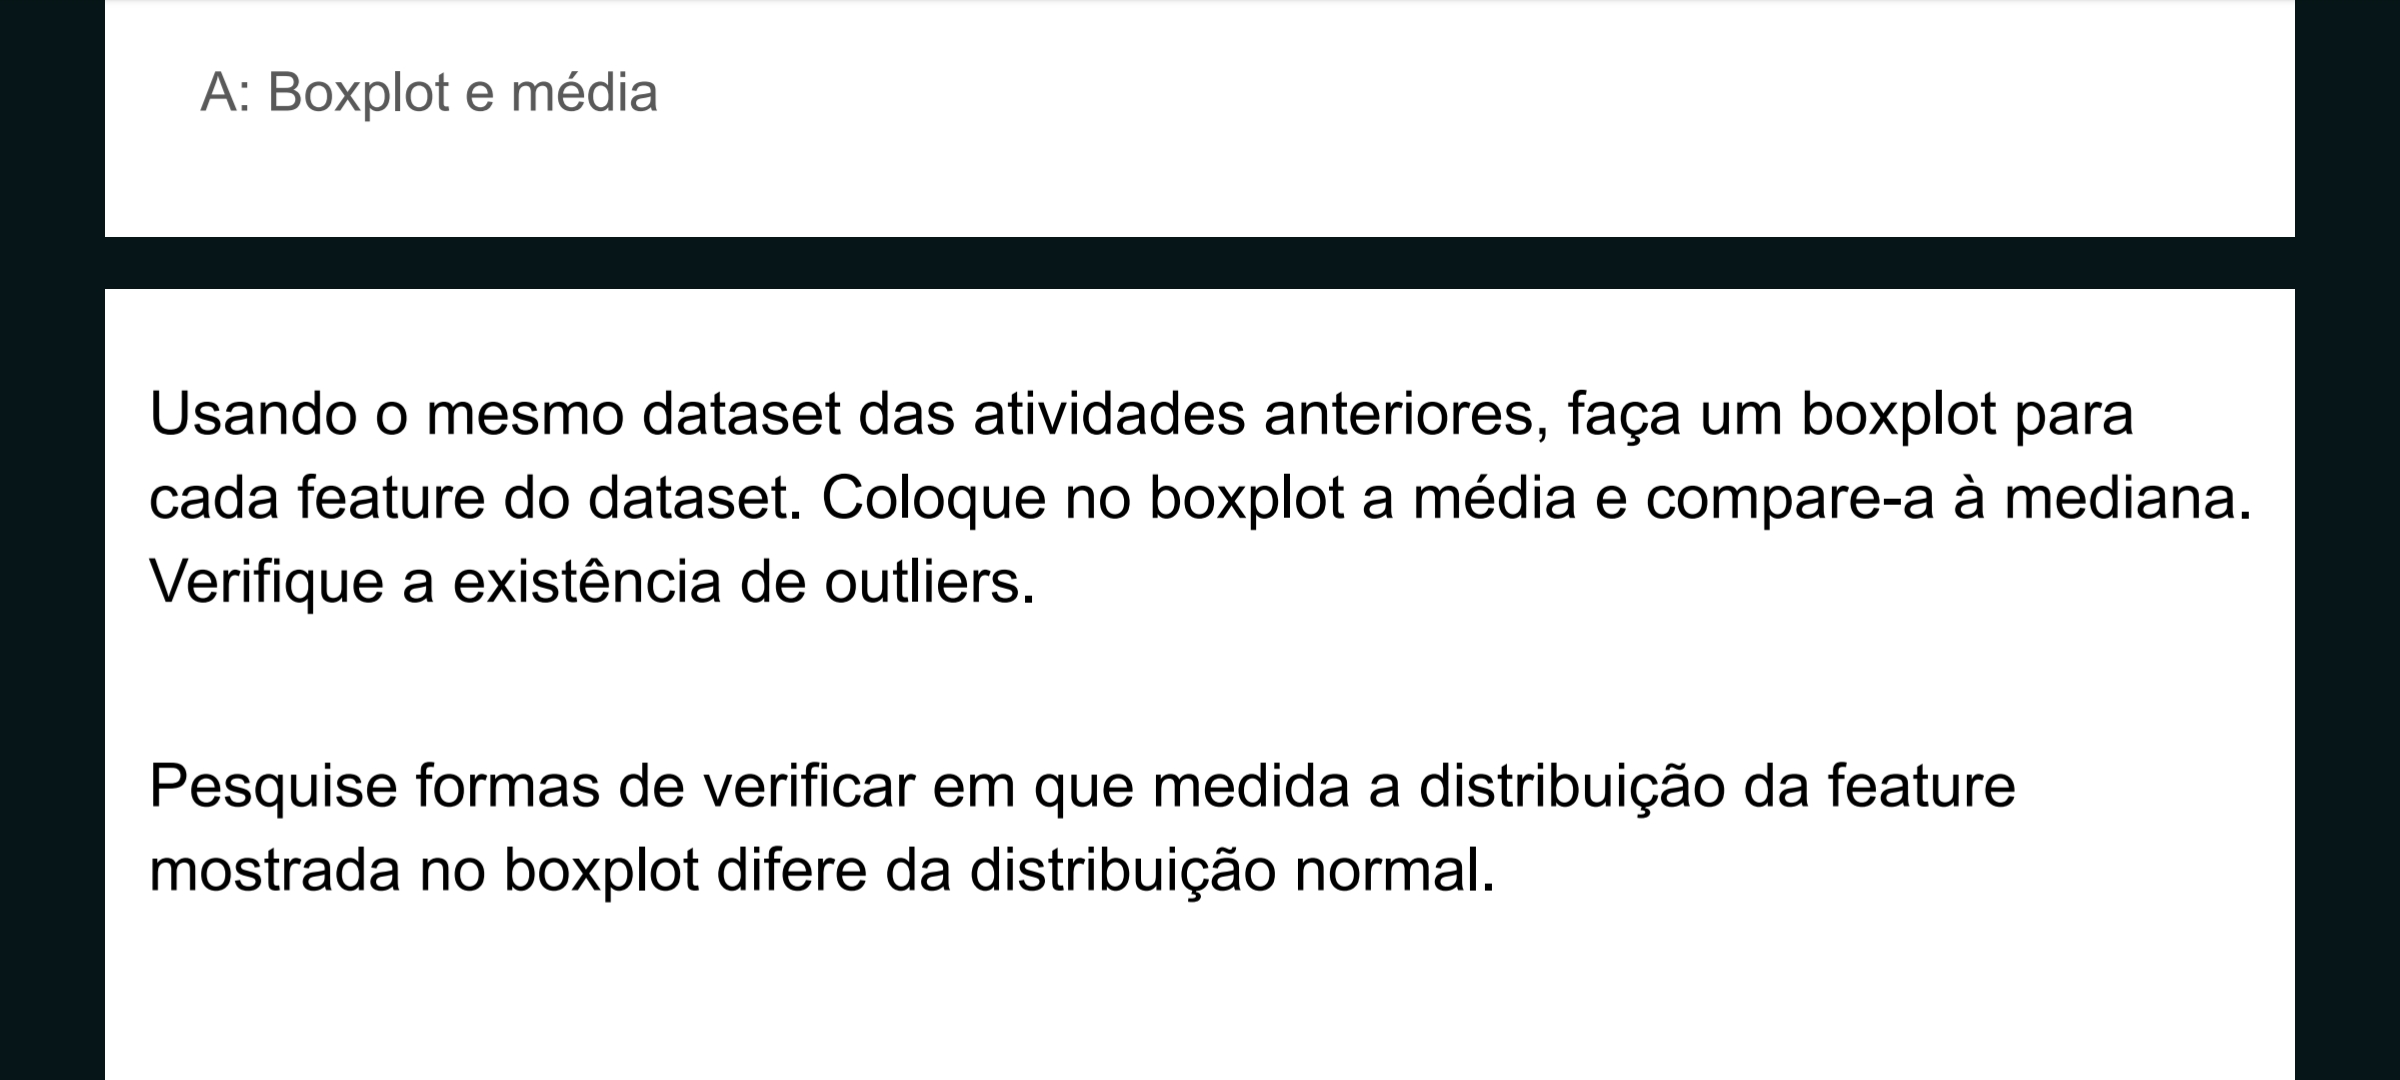

Aqui geramos o boxplot para cada feature numérica, calculando e sobrepondo explicitamente a mediana (linha interna do boxplot) e a média (marcador de diamante vermelho).

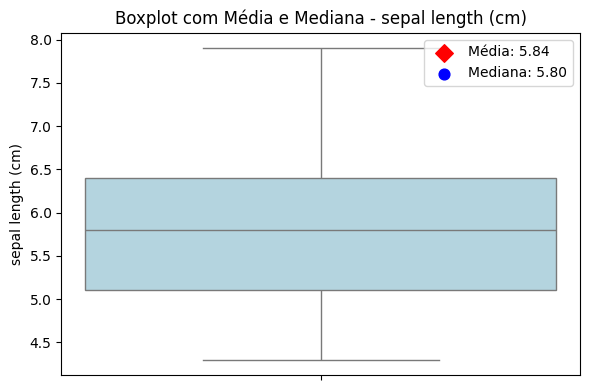

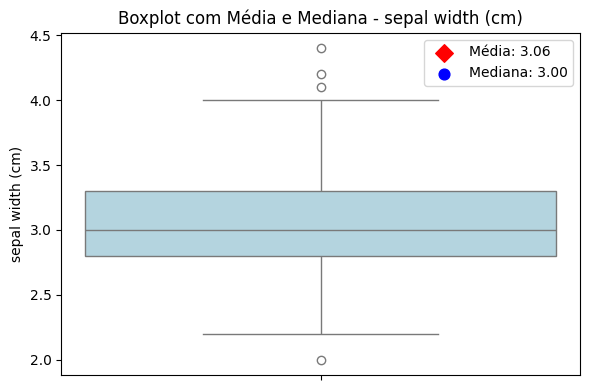

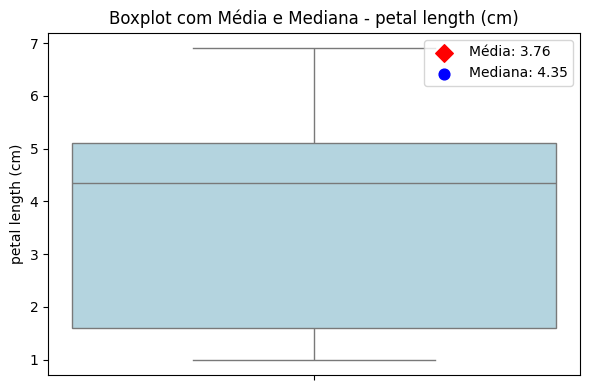

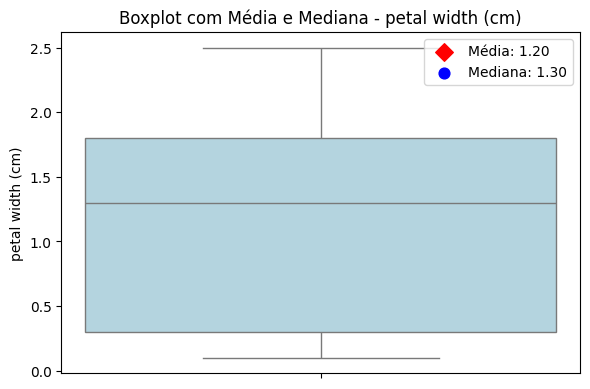

In [47]:
num_cols = df.select_dtypes(include=[np.number]).columns

for col in num_cols:
  plt.figure(figsize=(6, 4))
  ax = sns.boxplot(y=df[col], color='lightblue')

  mean_val = df[col].mean()
  median_val = df[col].median()

  # Adicionando média e mediana no gráfico
  plt.scatter(
      0, mean_val, color='red', marker='D', s=80, label=f'Média: {mean_val:.2f}'
  )
  plt.scatter(
      0,
      median_val,
      color='blue',
      marker='o',
      s=60,
      label=f'Mediana: {median_val:.2f}',
  )

  plt.title(f'Boxplot com Média e Mediana - {col}')
  plt.legend(loc='upper right')
  plt.tight_layout()
  plt.show()

## Verificação e Contagem de Outliers (Método IQR)

Esta célula calcula os limites inferiores e superiores usando o Intervalo Interquartil (IQR) para identificar quantitativamente quais e quantos pontos são considerados outliers em cada feature.

In [48]:
for col in num_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

  print(f'Feature: {col}')
  print(f'• Limites IQR: [{lower_bound:.2f}, {upper_bound:.2f}]')
  print(
      f'• Total de outliers detectados: {len(outliers)}'
      if len(outliers) > 0
      else '• Nenhum outlier detectado.'
  )
  print('-' * 40)

Feature: sepal length (cm)
• Limites IQR: [3.15, 8.35]
• Nenhum outlier detectado.
----------------------------------------
Feature: sepal width (cm)
• Limites IQR: [2.05, 4.05]
• Total de outliers detectados: 4
----------------------------------------
Feature: petal length (cm)
• Limites IQR: [-3.65, 10.35]
• Nenhum outlier detectado.
----------------------------------------
Feature: petal width (cm)
• Limites IQR: [-1.95, 4.05]
• Nenhum outlier detectado.
----------------------------------------


## Q-Q Plots (Comparação Visual com a Distribuição Normal)

O Q-Q Plot ajuda a verificar visualmente se os dados seguem uma distribuição normal, comparando os quantis dos seus dados com os quantis de uma distribuição teórica normal.

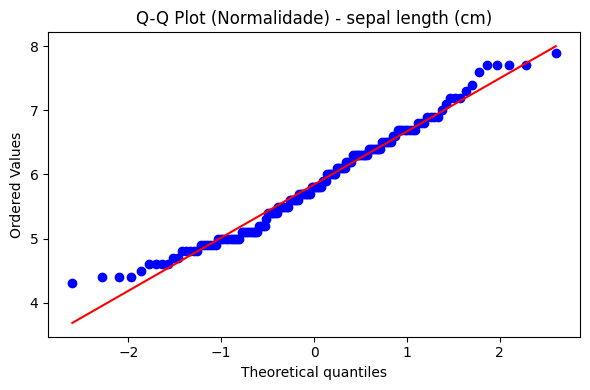

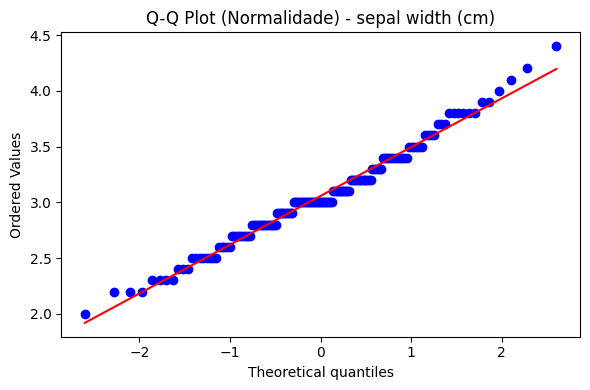

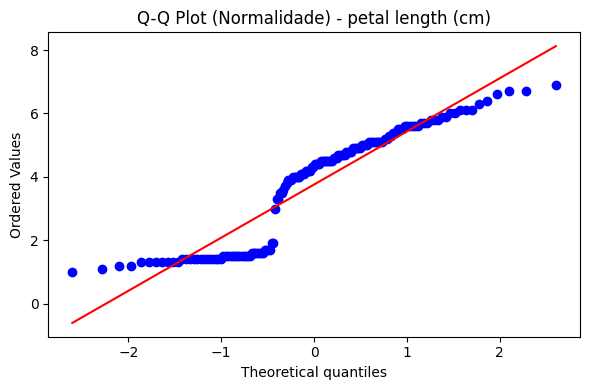

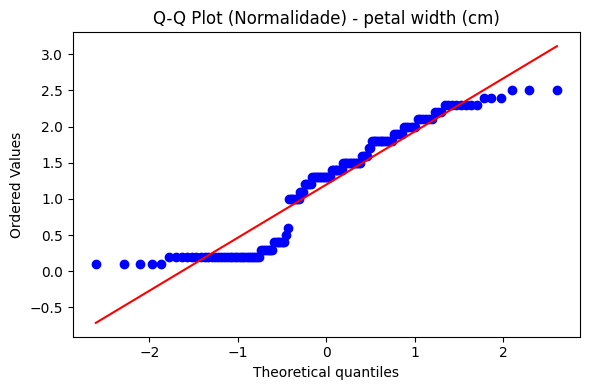

In [49]:
import scipy.stats as stats

for col in num_cols:
  plt.figure(figsize=(6, 4))
  stats.probplot(df[col], plot=plt)
  plt.title(f'Q-Q Plot (Normalidade) - {col}')
  plt.tight_layout()
  plt.show()

## Métricas de Forma (Assimetria e Curtose) e Teste Estatístico

Por fim, calculamos a Assimetria (Skewness) para medir o grau de desvio da simetria, a Curtose para medir o peso das caudas, e aplicamos o teste de Shapiro-Wilk para avaliar formalmente a normalidade.

In [50]:
for col in num_cols:
  skew = df[col].skew()
  kurt = df[col].kurtosis()
  stat, p_value = stats.shapiro(df[col])

  print(f'Feature: {col}')
  print(f'• Assimetria (Skewness): {skew:.4f} (Ideal para normal = 0)')
  print(f'• Curtose (Kurtosis): {kurt:.4f} (Ideal para normal = 0)')
  print(f'• Teste Shapiro-Wilk p-valor: {p_value:.4e}')

  if p_value < 0.05:
    print('  -> Conclusão: A distribuição difere da normal (Rejeita H0).')
  else:
    print(
        '  -> Conclusão: Não há evidências suficientes para rejeitar a'
        ' normalidade.'
    )
  print('=' * 50)

Feature: sepal length (cm)
• Assimetria (Skewness): 0.3149 (Ideal para normal = 0)
• Curtose (Kurtosis): -0.5521 (Ideal para normal = 0)
• Teste Shapiro-Wilk p-valor: 1.0181e-02
  -> Conclusão: A distribuição difere da normal (Rejeita H0).
Feature: sepal width (cm)
• Assimetria (Skewness): 0.3190 (Ideal para normal = 0)
• Curtose (Kurtosis): 0.2282 (Ideal para normal = 0)
• Teste Shapiro-Wilk p-valor: 1.0115e-01
  -> Conclusão: Não há evidências suficientes para rejeitar a normalidade.
Feature: petal length (cm)
• Assimetria (Skewness): -0.2749 (Ideal para normal = 0)
• Curtose (Kurtosis): -1.4021 (Ideal para normal = 0)
• Teste Shapiro-Wilk p-valor: 7.4123e-10
  -> Conclusão: A distribuição difere da normal (Rejeita H0).
Feature: petal width (cm)
• Assimetria (Skewness): -0.1030 (Ideal para normal = 0)
• Curtose (Kurtosis): -1.3406 (Ideal para normal = 0)
• Teste Shapiro-Wilk p-valor: 1.6805e-08
  -> Conclusão: A distribuição difere da normal (Rejeita H0).


# B: Estimando um intervalo de confiança para a média

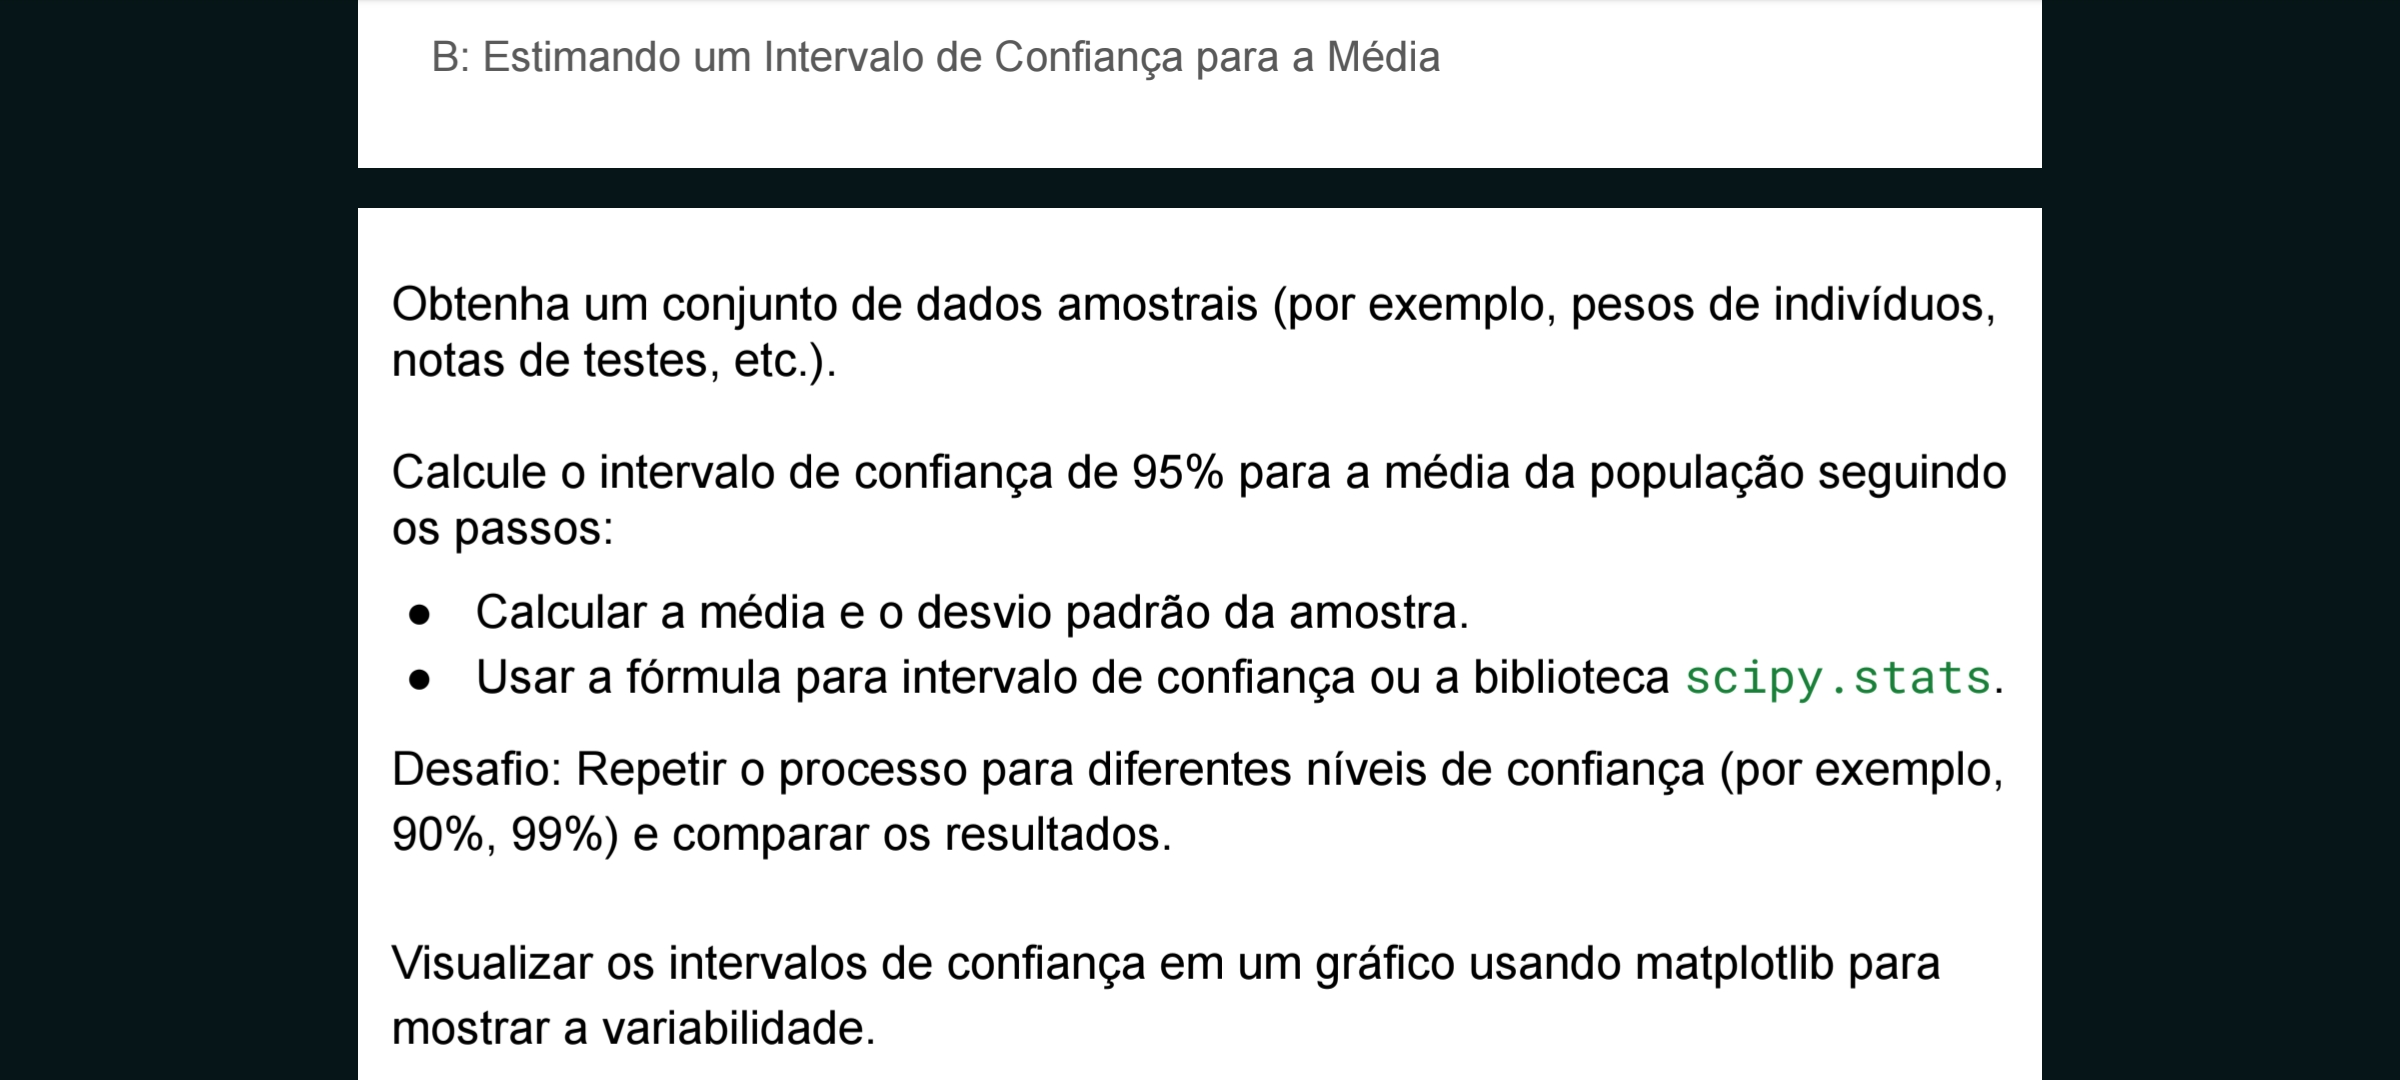

Aqui criamos a nossa amostra de dados (pesos de indivíduos) e calculamos a média amostral, o desvio padrão e o erro padrão da média, preparando o terreno para a inferência estatística.

In [51]:
import numpy as np
import scipy.stats as stats

# 1. Conjunto de dados amostrais simulado (ex: pesos de 50 indivíduos em kg)
np.random.seed(42)  # Garante reprodutibilidade
pesos = np.random.normal(loc=72.0, scale=8.5, size=50)

# 2. Cálculo da Média e do Desvio Padrão da Amostra
n = len(pesos)
media_amostral = np.mean(pesos)
desvio_padrao_amostral = np.std(
    pesos, ddof=1
)  # ddof=1 para desvio padrão amostral (n-1)
erro_padrao = desvio_padrao_amostral / np.sqrt(n)

print(f'Tamanho da Amostra (n): {n}')
print(f'Média Amostral: {media_amostral:.2f} kg')
print(f'Desvio Padrão Amostral: {desvio_padrao_amostral:.2f} kg')
print(f'Erro Padrão da Média: {erro_padrao:.2f}')

Tamanho da Amostra (n): 50
Média Amostral: 70.08 kg
Desvio Padrão Amostral: 7.94 kg
Erro Padrão da Média: 1.12


## Cálculo dos Intervalos de Confiança (90%, 95% e 99%)

Utilizamos a distribuição t de Student (ideal para quando o desvio padrão populacional é desconhecido e a amostra é finita) via scipy.stats.t.interval para computar os intervalos para diferentes níveis de confiança.


In [52]:
# Níveis de confiança solicitados
niveis_confianca = [0.90, 0.95, 0.99]
resultados_ic = {}

for nivel in niveis_confianca:
  # Calculando o intervalo usando scipy.stats
  limite_inf, limite_sup = stats.t.interval(
      confidence=nivel, df=n - 1, loc=media_amostral, scale=erro_padrao
  )

  # Calculando a margem de erro
  margem_erro = (limite_sup - limite_inf) / 2

  resultados_ic[nivel] = {
      'inf': limite_inf,
      'sup': limite_sup,
      'margem': margem_erro,
  }

  print(
      f'Intervalo de Confiança de {int(nivel*100)}%: [{limite_inf:.2f},'
      f' {limite_sup:.2f}] (Margem de Erro: ±{margem_erro:.2f})'
  )

Intervalo de Confiança de 90%: [68.20, 71.97] (Margem de Erro: ±1.88)
Intervalo de Confiança de 95%: [67.83, 72.34] (Margem de Erro: ±2.26)
Intervalo de Confiança de 99%: [67.08, 73.09] (Margem de Erro: ±3.01)


## Tabela Comparativa dos Intervalos

Organizamos os resultados em um DataFrame do Pandas para facilitar a comparação visual de como a amplitude e a margem de erro se expandem à medida que aumentamos o nível de confiança.

In [53]:
import pandas as pd

# Criando a tabela de comparação
dados_tabela = []
for nivel, vals in resultados_ic.items():
  dados_tabela.append({
      'Nível de Confiança': f'{int(nivel*100)}%',
      'Limite Inferior': round(vals['inf'], 2),
      'Limite Superior': round(vals['sup'], 2),
      'Amplitude (Largura)': round(vals['sup'] - vals['inf'], 2),
      'Margem de Erro': round(vals['margem'], 2),
  })

df_comparacao = pd.DataFrame(dados_tabela)
display(df_comparacao)

,Nível de Confiança,Limite Inferior,Limite Superior,Amplitude (Largura),Margem de Erro
0,90%,68.20,71.97,3.76,1.88
1,95%,67.83,72.34,4.51,2.26
2,99%,67.08,73.09,6.02,3.01


## Visualização Gráfica da Variabilidade

Por fim, plotamos um gráfico de erros utilizando o matplotlib para ilustrar claramente a variação dos intervalos de confiança em torno da média amostral.

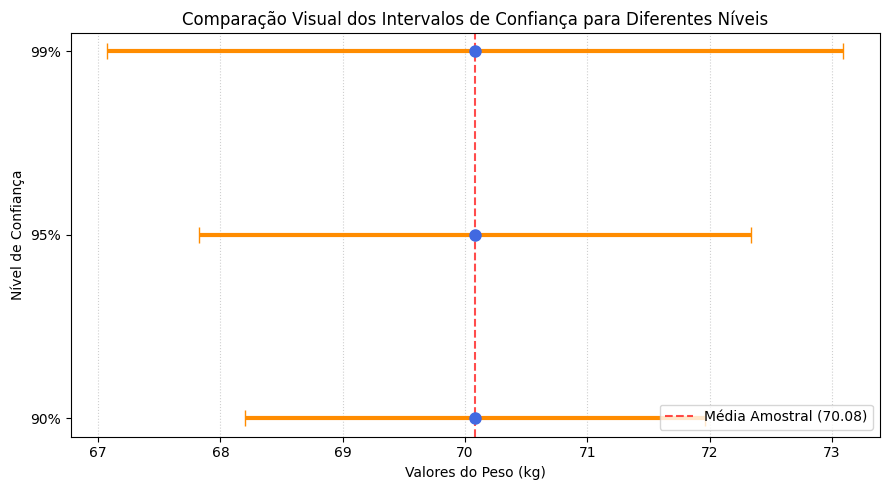

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

niveis_str = ['90%', '95%', '99%']
infs = [
    resultados_ic[0.90]['inf'],
    resultados_ic[0.95]['inf'],
    resultados_ic[0.99]['inf'],
]
sups = [
    resultados_ic[0.90]['sup'],
    resultados_ic[0.95]['sup'],
    resultados_ic[0.99]['sup'],
]

y_pos = np.arange(len(niveis_str))
centros = [media_amostral] * len(niveis_str)
erros = [(sups[i] - infs[i]) / 2 for i in range(len(niveis_str))]

# Plotando as barras de erro
plt.errorbar(
    centros,
    y_pos,
    xerr=erros,
    fmt='o',
    color='royalblue',
    ecolor='darkorange',
    elinewidth=3,
    capsize=6,
    markersize=8,
)

# Linha vertical indicando a média amostral central
plt.axvline(
    media_amostral,
    color='red',
    linestyle='--',
    alpha=0.7,
    label=f'Média Amostral ({media_amostral:.2f})',
)

plt.yticks(y_pos, niveis_str)
plt.xlabel('Valores do Peso (kg)')
plt.ylabel('Nível de Confiança')
plt.title(
    'Comparação Visual dos Intervalos de Confiança para Diferentes Níveis'
)
plt.legend(loc='lower right')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# C: P-value em um Teste de Hipótese

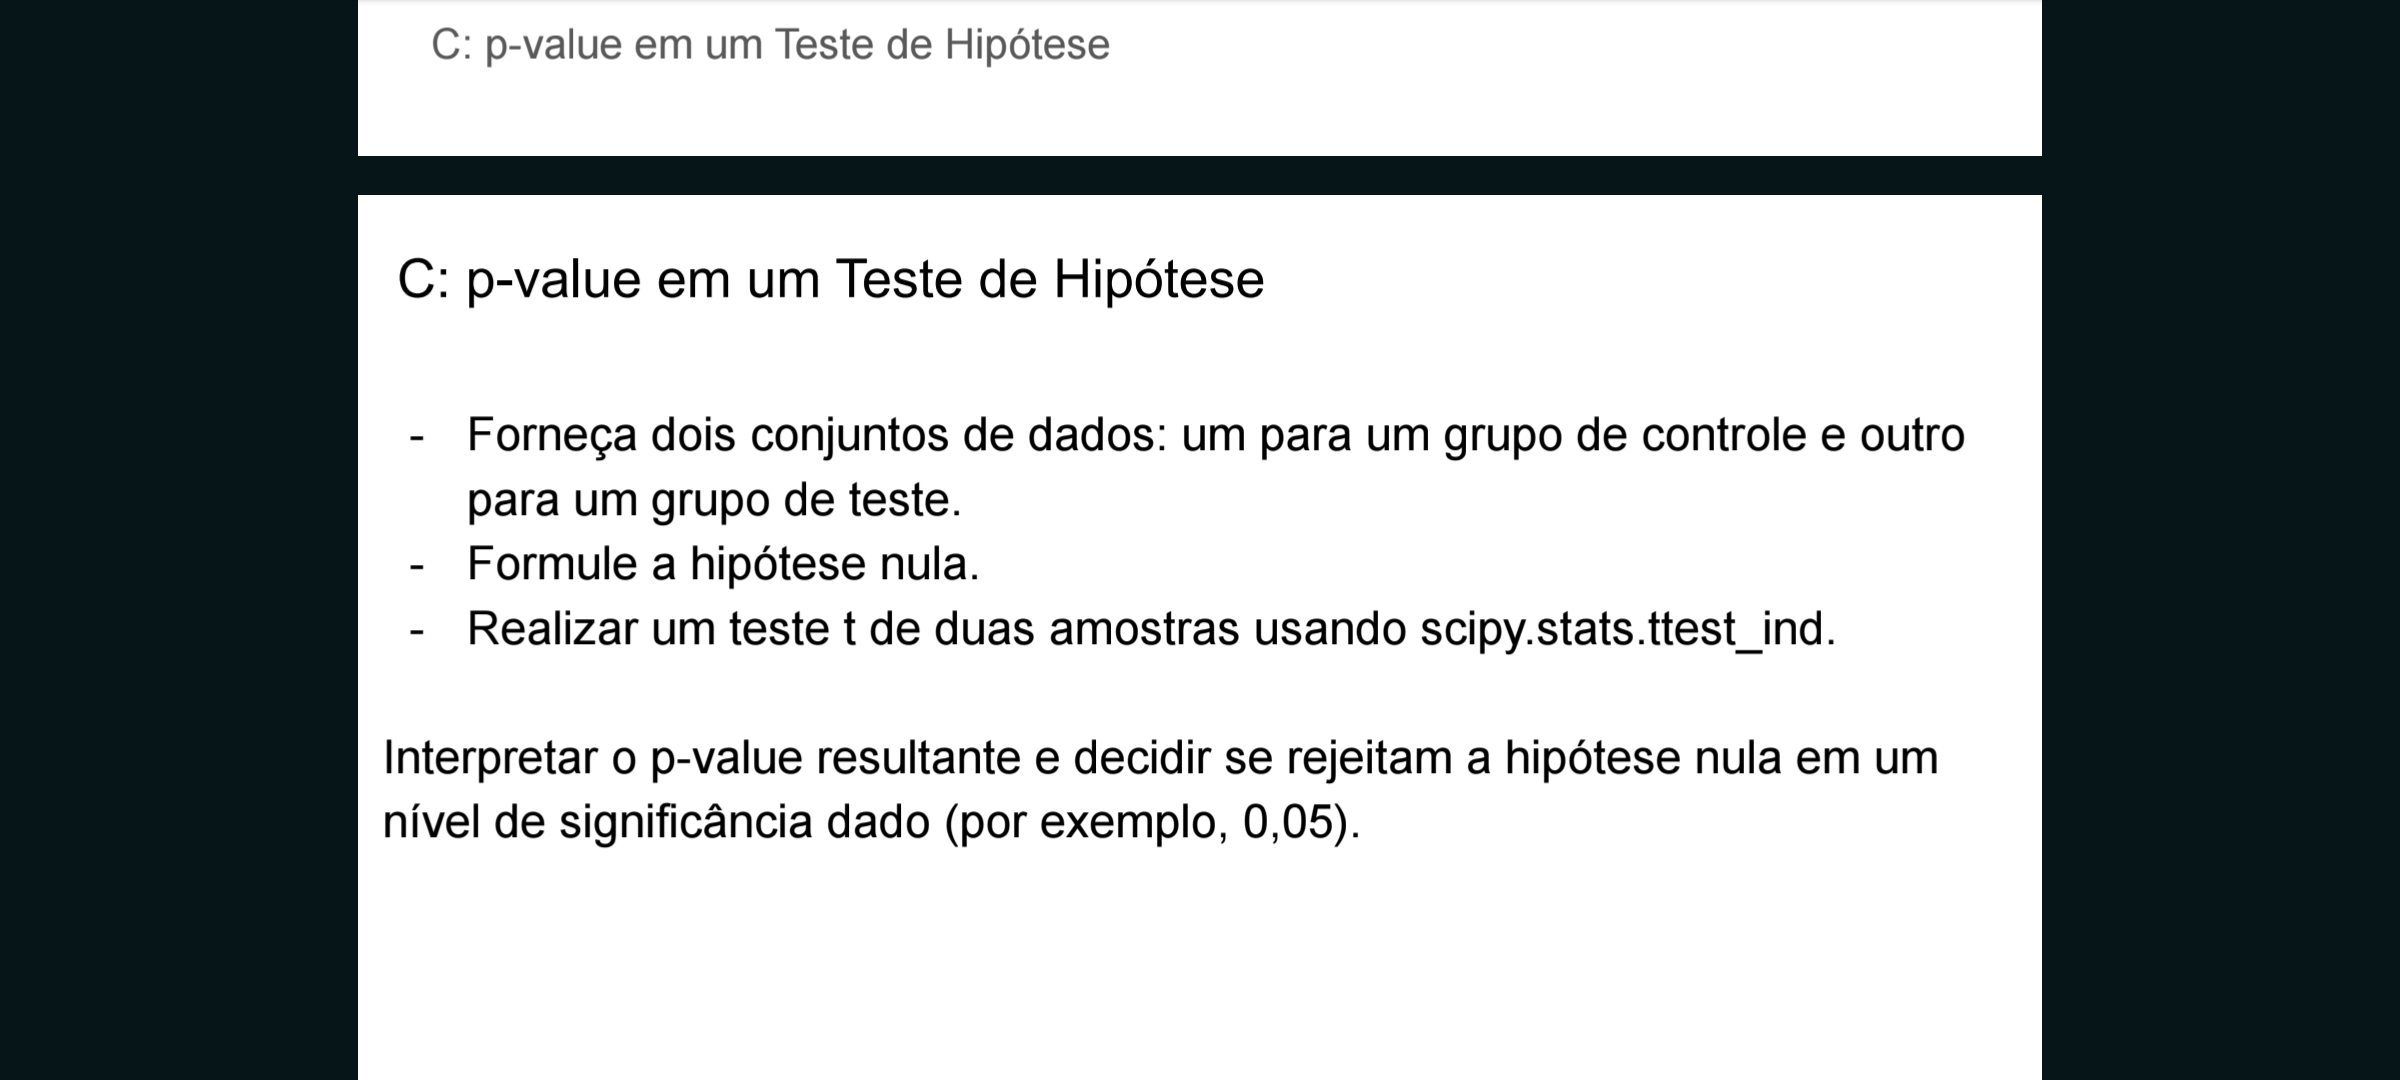

Nesta etapa, geramos dois conjuntos de dados simulados (por exemplo, o tempo de carregamento ou taxa de conversão, ou notas de teste de dois métodos de ensino diferentes) para representar o Grupo de Controle e o Grupo de Teste.

In [55]:
import numpy as np
import scipy.stats as stats

# Definindo a semente para reprodutibilidade
np.random.seed(42)

# Simulando dados (ex: pontuação de desempenho de funcionários sob dois treinamentos diferentes)
# Grupo de Controle: Média de 70 e desvio padrão de 8
grupo_controle = np.random.normal(loc=70.0, scale=8.0, size=40)

# Grupo de Teste: Média de 74 e desvio padrão de 9 (com ligeira melhora)
grupo_teste = np.random.normal(loc=74.0, scale=9.0, size=40)

print(f'Tamanho do Grupo Controle: {len(grupo_controle)}')
print(f'Média do Grupo Controle: {np.mean(grupo_controle):.2f}')
print(f'Tamanho do Grupo Teste: {len(grupo_teste)}')
print(f'Média do Grupo Teste: {np.mean(grupo_teste):.2f}')

Tamanho do Grupo Controle: 40
Média do Grupo Controle: 68.25
Tamanho do Grupo Teste: 40
Média do Grupo Teste: 73.74


## Formulação das Hipóteses e Execução do Teste t de Student

Definimos formalmente a Hipótese Nula ($H_0$) e a Hipótese Alternativa ($H_1$), e em seguida utilizamos a função scipy.stats.ttest_ind para realizar o teste t de duas amostras independentes.

In [56]:
# FORMULAÇÃO DAS HIPÓTESES:
# H0 (Hipótese Nula): Não há diferença significativa entre as médias dos dois grupos (média_controle = média_teste).
# H1 (Hipótese Alternativa): Há uma diferença significativa entre as médias dos dois grupos (média_controle != média_teste).

# Realizando o teste t de Student para duas amostras independentes
t_stat, p_value = stats.ttest_ind(grupo_controle, grupo_teste)

print(f'Estatística t: {t_stat:.4f}')
print(f'P-value obtido: {p_value:.6f}')

Estatística t: -3.0039
P-value obtido: 0.003582


## Interpretação do P-value e Conclusão Estatística

Comparamos o P-value resultante com o nível de significância escolhido ($\alpha = 0,05$) para tomar a decisão de rejeitar ou não a hipótese nula.

In [57]:
# Nível de significância (alfa) definido
alfa = 0.05

print(f'Nível de Significância (alfa): {alfa}')
print(f'P-value calculado: {p_value:.6f}')
print('-' * 40)

if p_value < alfa:
  print(
      'CONCLUSÃO: Como o P-value é menor que o nível de significância (0.05),'
  )
  print(
      'rejeitamos a Hipótese Nula (H0). Existe evidência estatística'
      ' significativa'
  )
  print('de que há diferença entre os grupos.')
else:
  print(
      'CONCLUSÃO: Como o P-value é maior ou igual ao nível de significância'
      ' (0.05),'
  )
  print(
      'não temos evidências suficientes para rejeitar a Hipótese Nula (H0).'
  )
  print('A diferença observada pode ser apenas fruto do acaso.')

Nível de Significância (alfa): 0.05
P-value calculado: 0.003582
----------------------------------------
CONCLUSÃO: Como o P-value é menor que o nível de significância (0.05),
rejeitamos a Hipótese Nula (H0). Existe evidência estatística significativa
de que há diferença entre os grupos.


# D: Nivel de significância

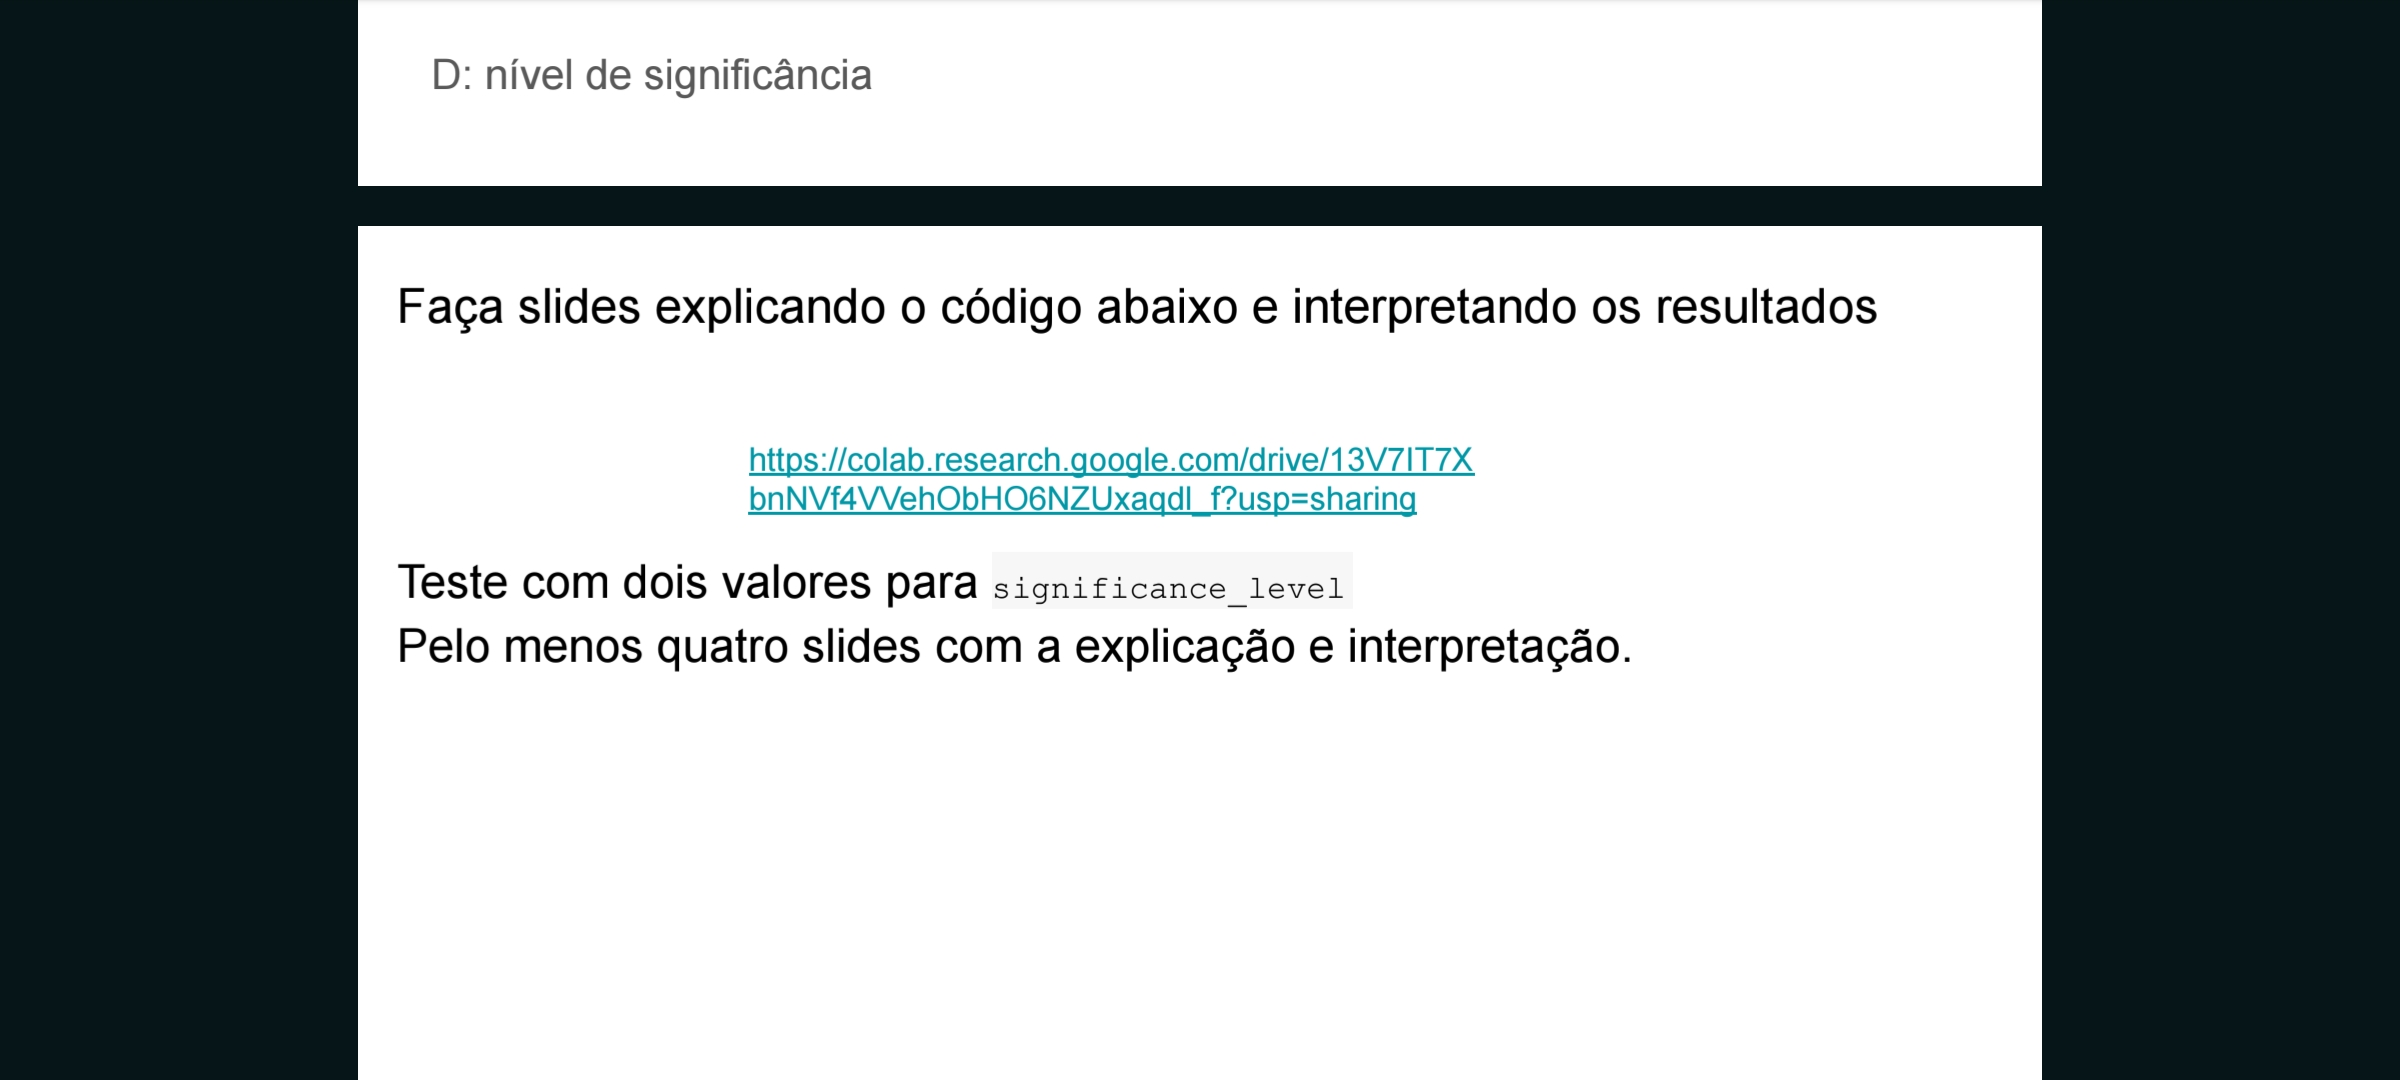

In [58]:
import numpy as np
from scipy.stats import ttest_ind

# Parâmetros da simulação
num_simulations = 10000
sample_size = 30
true_mean = 50
true_std = 10

# Testando com dois níveis de significância diferentes
niveis_alfa = [0.05, 0.01]

for significance_level in niveis_alfa:
  significant_results = 0

  # Executando a simulação 10.000 vezes
  for _ in range(num_simulations):
    # ATENÇÃO: Ambos os grupos vêm EXATAMENTE da mesma distribuição!
    # Isso significa que a Hipótese Nula (H0) é 100% verdadeira aqui.
    group1 = np.random.normal(true_mean, true_std, sample_size)
    group2 = np.random.normal(true_mean, true_std, sample_size)

    # Realiza o teste t de Student
    t_stat, p_value = ttest_ind(group1, group2)

    # Verifica se rejeitamos H0 incorretamente (p-value menor que alfa)
    if p_value < significance_level:
      significant_results += 1

  # Calcula a proporção de falsos positivos
  proportion_significant = significant_results / num_simulations

  print(f'--- Resultados para Alfa = {significance_level} ---')
  print(f'Número de simulações: {num_simulations}')
  print(
      'Proporção de resultados significativos (Taxa de Erro Tipo I):'
      f' {proportion_significant:.4f} ({proportion_significant * 100:.2f}%)'
  )
  print('\n')

--- Resultados para Alfa = 0.05 ---
Número de simulações: 10000
Proporção de resultados significativos (Taxa de Erro Tipo I): 0.0514 (5.14%)


--- Resultados para Alfa = 0.01 ---
Número de simulações: 10000
Proporção de resultados significativos (Taxa de Erro Tipo I): 0.0085 (0.85%)




## Explicação do Código

**Geração sob a Hipótese Nula**: Repare que group1 e group2 são gerados usando os mesmos parâmetros (true_mean = 50, true_std = 10). Na realidade, não há diferença entre os dois grupos. Logo, a Hipótese Nula ($H_0$) é verdadeira em todas as iterações.

**O Loop de Simulação (for _ in range(num_simulations):):** O teste t é executado 10.000 vezes para observar o comportamento dos $p$-values no longo prazo.

**Contagem de Falsos Positivos:** Se o $p$-value obtido for menor que o significance_level ($\alpha$), o código contabiliza como um resultado "estatisticamente significativo". Como sabemos que os grupos são iguais, qualquer sinalização de diferença é um Erro Tipo I (rejeitar $H_0$ quando ela é verdadeira).

## Interpretação dos Resultados

**O que o resultado mostra**: A proporção de resultados significativos ($5\%$ para $\alpha = 0.05$ e $1\%$ para $\alpha = 0.01$) será praticamente idêntica ao valor de $\alpha$ escolhido.

**O significado prático:** Isso prova que o nível de significância ($\alpha$) que você define antes de um teste estatístico é, na verdade, a probabilidade máxima de cometer um falso positivo (ou seja, de declarar que existe um efeito ou diferença quando, na verdade, ele ocorreu puramente por acaso devido à variação amostral).

# E: Intervalo de confiança e codigo

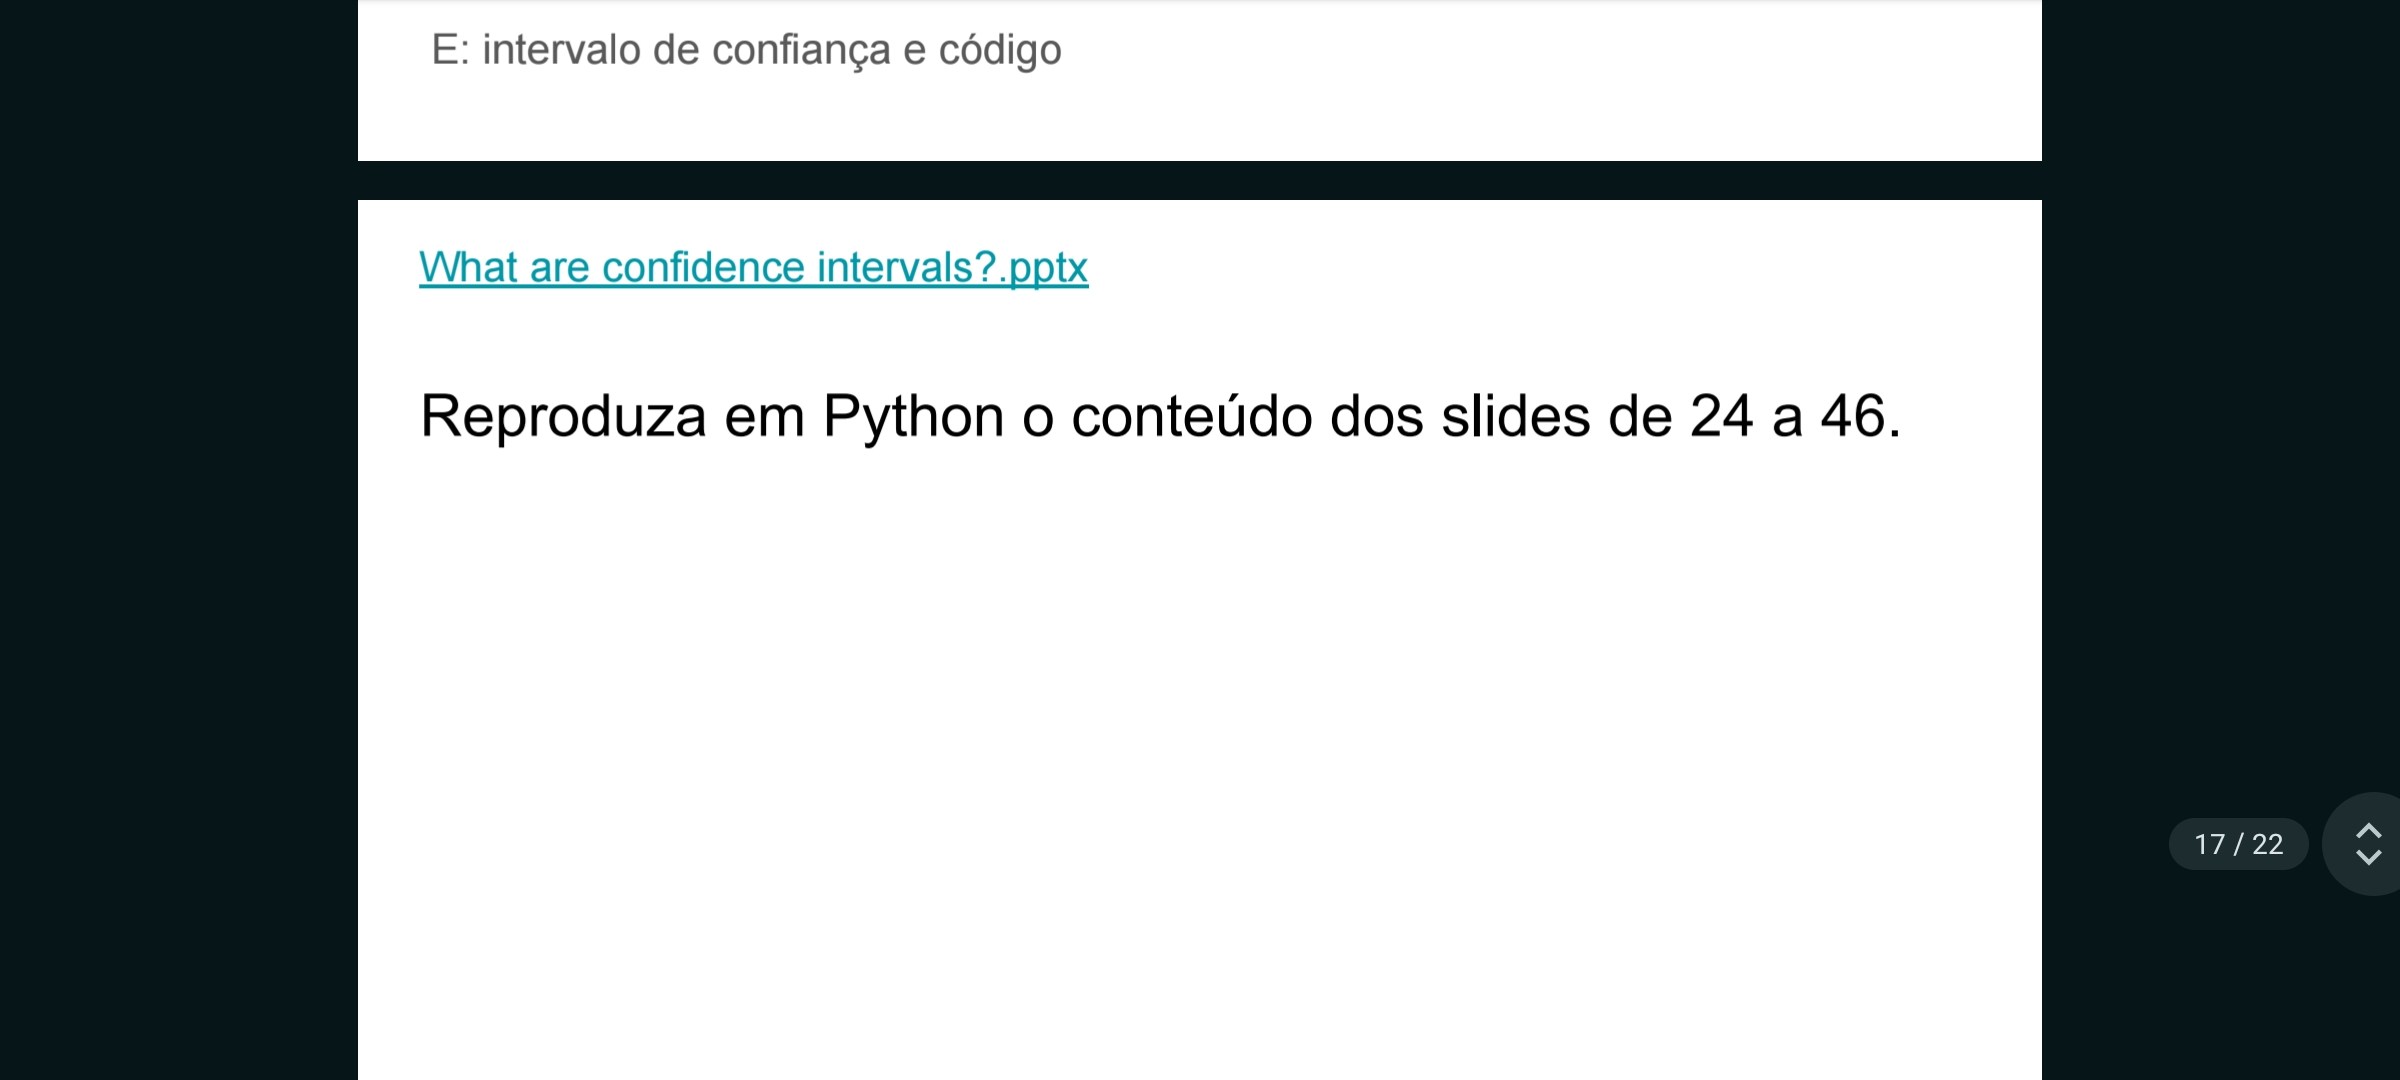

Esta célula simula o conjunto de dados apresentado nos slides (amostra de $n = 50$ mulheres contendo o ID e o Batimento Cardíaco em BPM).

In [59]:
import numpy as np
import pandas as pd
import scipy.stats as stats

# Definindo semente e simulando o dataset de 50 mulheres (conforme os slides)
np.random.seed(42)
n = 50
woman_ids = [f"{i:03d}" for i in range(1, n + 1)]
heart_rates = np.random.normal(
    loc=78.0, scale=12.0, size=n
)  # Média simulada de repouso
heart_rates = np.clip(
    heart_rates, 55, 120
)  # Limitando a valores realistas de BPM

df_heart = pd.DataFrame({'Woman ID': woman_ids, 'Heart Rate (BPM)': heart_rates})

# Visualizando as primeiras linhas (exatamente como na tabela do slide)
df_heart.head(6)

,Woman ID,Heart Rate (BPM)
0,001,83.960570
1,002,76.340828
2,003,85.772262
3,004,96.276358
4,005,75.190160
5,006,75.190357


## Intervalo de Confiança para a Média Populacional ($\mu$)

Calculamos o intervalo de confiança para a média do batimento cardíaco usando a fórmula apresentada no slide esquerdo: $\bar{x} \pm t \left(\frac{s}{\sqrt{n}}\right)$.

In [60]:
# 1. Estatísticas da Amostra para a Média
media_amostral = df_heart['Heart Rate (BPM)'].mean()
desvio_padrao = df_heart['Heart Rate (BPM)'].std(ddof=1)
erro_padrao_media = desvio_padrao / np.sqrt(n)

# 2. Intervalo de Confiança de 95% para a Média Populacional (mu)
confianca = 0.95
inf_mu, sup_mu = stats.t.interval(
    confidence=confianca,
    df=n - 1,
    loc=media_amostral,
    scale=erro_padrao_media,
)

print(
    '--- Estimativa da Média Populacional (μ) ---'
    f' (Média Amostral: {media_amostral:.2f})'
)
print(f'IC 95% para o Batimento Cardíaco Médio: [{inf_mu:.2f}, {sup_mu:.2f}] bpm')

--- Estimativa da Média Populacional (μ) --- (Média Amostral: 75.30)
IC 95% para o Batimento Cardíaco Médio: [72.13, 78.48] bpm


## Intervalo de Confiança para a Proporção Populacional ($\pi$)

Calculamos o intervalo de confiança para a proporção de mulheres que possuem batimento cardíaco "alto" ($\ge 100\text{ bpm}$), utilizando a fórmula do slide direito: $p \pm z \sqrt{\frac{p(1-p)}{n}}$.

In [61]:
# Definindo o critério de "Heart Rate alto" (>= 100 bpm conforme o slide)
condicao_alto = df_heart['Heart Rate (BPM)'] >= 100
sucessos = condicao_alto.sum()

# Proporção amostral (p)
p_amostral = sucessos / n
erro_padrao_prop = np.sqrt((p_amostral * (1 - p_amostral)) / n)

# Valor crítico Z para 95% de confiança (distribuição normal padrão)
z_score = stats.norm.ppf(1 - (1 - 0.95) / 2)

margem_erro_prop = z_score * erro_padrao_prop
inf_pi = max(0, p_amostral - margem_erro_prop)
sup_pi = min(1, p_amostral + margem_erro_prop)

print(
    '--- Estimativa da Proporção Populacional (π) ---'
    f' (Proporção Amostral p: {p_amostral:.4f})'
)
print(f'Mulheres com batimento >= 100 bpm na amostra: {sucessos} de {n}')
print(f'IC 95% para a Proporção Populacional: [{inf_pi:.4f}, {sup_pi:.4f}]')
print(f'Em porcentagem: [{inf_pi*100:.1f}%, {sup_pi*100:.1f}%]')

--- Estimativa da Proporção Populacional (π) --- (Proporção Amostral p: 0.0200)
Mulheres com batimento >= 100 bpm na amostra: 1 de 50
IC 95% para a Proporção Populacional: [0.0000, 0.0588]
Em porcentagem: [0.0%, 5.9%]


## Visualização Gráfica Comparativa (Média vs Proporção)

Por fim, criamos os gráficos estruturados lado a lado para ilustrar a estimativa visual de ambos os parâmetros abordados nos slides.



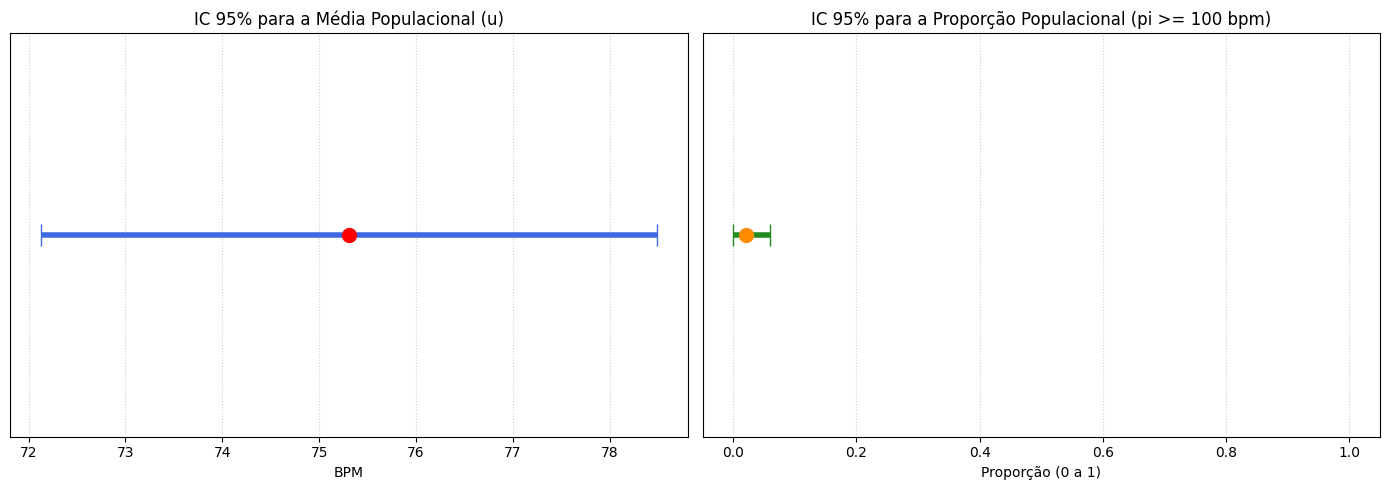

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Média Populacional
axes[0].errorbar(
    [media_amostral],
    [1],
    xerr=[[media_amostral - inf_mu], [sup_mu - media_amostral]],
    fmt='o',
    color='red',
    ecolor='royalblue',
    elinewidth=4,
    capsize=8,
    markersize=10,
)
axes[0].set_yticks([])
axes[0].set_xlabel('BPM')
axes[0].set_title('IC 95% para a Média Populacional (u)')
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# Gráfico 2: Proporção Populacional
axes[1].errorbar(
    [p_amostral],
    [1],
    xerr=[[p_amostral - inf_pi], [sup_pi - p_amostral]],
    fmt='o',
    color='darkorange',
    ecolor='forestgreen',
    elinewidth=4,
    capsize=8,
    markersize=10,
)
axes[1].set_yticks([])
axes[1].set_xlabel('Proporção (0 a 1)')
axes[1].set_title('IC 95% para a Proporção Populacional (pi >= 100 bpm)')
axes[1].set_xlim(-0.05, 1.05)
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# F: P-value e moeda

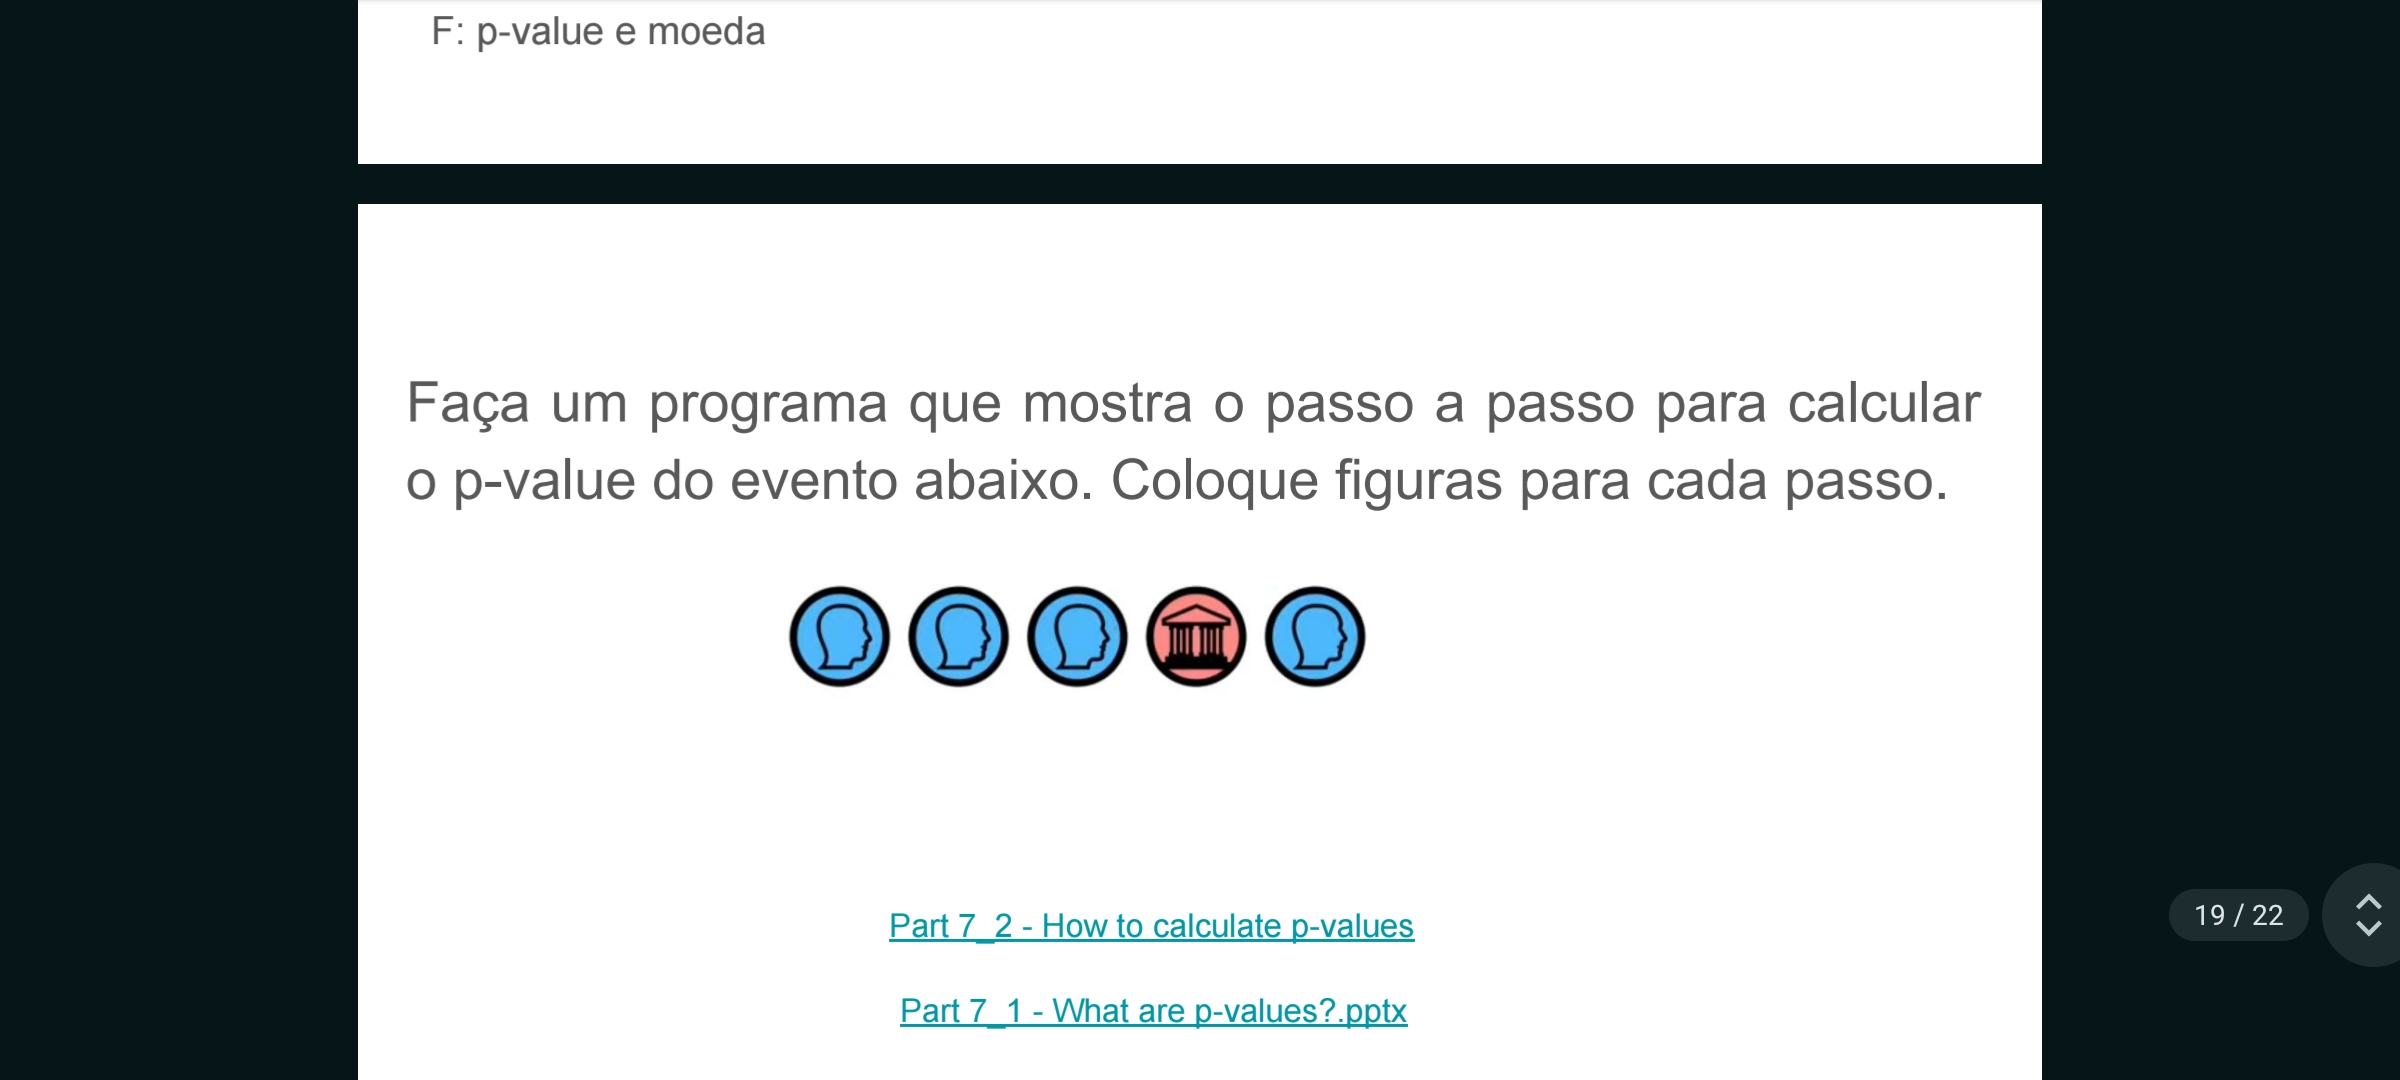

## Passo 1 - Definir Dados e Hipóteses (Com Gráfico Inicial da Amostra)

Passo 1: Definir Hipóteses e Dados
• Total de lançamentos (n): 5
• Caras observadas: 3 | Coroas observadas: 2
• H0 (Nula): A moeda é justa (p = 0.5)
• H1 (Alternativa): A moeda não é justa (p != 0.5)



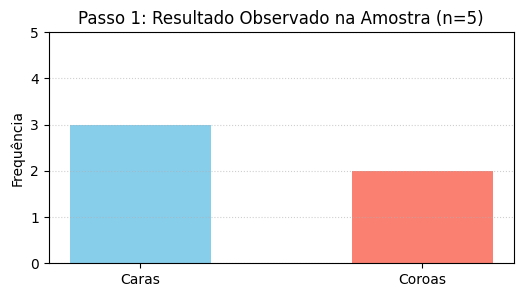

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Dados observados: 5 lançamentos (ex: 3 Caras e 2 Coroas, ou [Cara, Cara, Cara, Coroa, Coroa])
amostra = ['Cara', 'Cara', 'Cara', 'Coroa', 'Coroa']
n = len(amostra)
caras_observadas = amostra.count('Cara')
coroas_observadas = amostra.count('Coroa')

print(f'Passo 1: Definir Hipóteses e Dados')
print(f'• Total de lançamentos (n): {n}')
print(f'• Caras observadas: {caras_observadas} | Coroas observadas: {coroas_observadas}')
print(f'• H0 (Nula): A moeda é justa (p = 0.5)')
print(f'• H1 (Alternativa): A moeda não é justa (p != 0.5)\n')

# Figura do Passo 1: Visualização da Amostra
plt.figure(figsize=(6, 3))
categorias = ['Caras', 'Coroas']
valores = [caras_observadas, coroas_observadas]
plt.bar(categorias, valores, color=['skyblue', 'salmon'], width=0.5)
plt.ylim(0, n)
plt.title(f'Passo 1: Resultado Observado na Amostra (n={n})')
plt.ylabel('Frequência')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

## Passo 2 & 3 - Modelar a Distribuição Nula (Distribuição Binomial)

Passo 2 e 3: Modelando a Distribuição Nula
• Probabilidade de cada número de Caras de 0 a 5 sob H0:
  - 0 Caras: 0.0312 (3.1%)
  - 1 Caras: 0.1562 (15.6%)
  - 2 Caras: 0.3125 (31.2%)
  - 3 Caras: 0.3125 (31.2%)
  - 4 Caras: 0.1562 (15.6%)
  - 5 Caras: 0.0312 (3.1%)


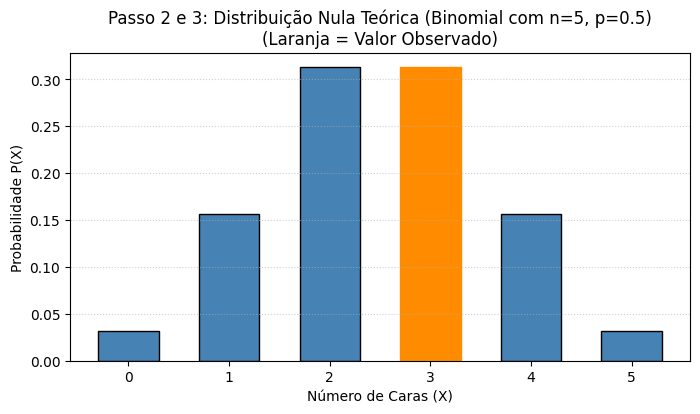

In [64]:
import scipy.stats as stats

# Parâmetros da Binomial sob H0 (p = 0.5)
p_nulo = 0.5
k_valores = np.arange(0, n + 1)
probabilidades = stats.binom.pmf(k_valores, n, p_nulo)

print(f'Passo 2 e 3: Modelando a Distribuição Nula')
print(f'• Probabilidade de cada número de Caras de 0 a 5 sob H0:')
for k, prob in zip(k_valores, probabilidades):
    print(f'  - {k} Caras: {prob:.4f} ({prob*100:.1f}%)')

# Figura dos Passos 2 e 3: Gráfico da Distribuição Binomial Teórica
plt.figure(figsize=(8, 4))
bars = plt.bar(k_valores, probabilidades, color='steelblue', edgecolor='black', width=0.6)

# Destacando o valor observado
bars[caras_observadas].set_color('darkorange')

plt.title('Passo 2 e 3: Distribuição Nula Teórica (Binomial com n=5, p=0.5)\n(Laranja = Valor Observado)')
plt.xlabel('Número de Caras (X)')
plt.ylabel('Probabilidade P(X)')
plt.xticks(k_valores)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

## Passo 4 & 5 - Cálculo do P-Value (Bicaudal) e Conclusão

Passo 4 e 5: Cálculo do P-Value e Conclusão
• P-value calculado (bicaudal): 1.0000
• Nível de significância (alfa): 0.05
---------------------------------------------
Conclusão: Não rejeitamos H0. Não há evidência suficiente para dizer que a moeda é viciada (é consistente com o acaso).


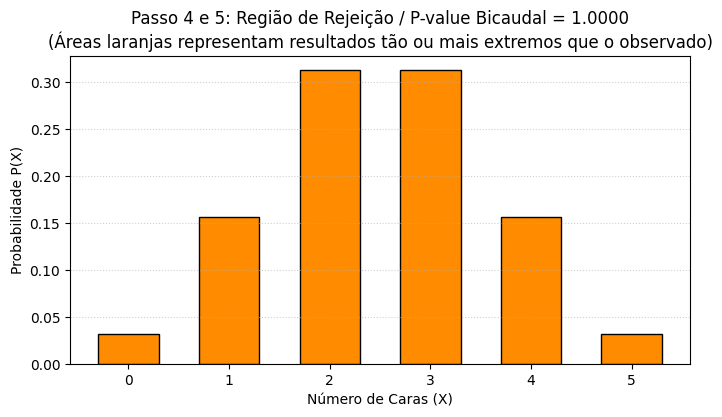

In [65]:
# Cálculo do P-value bicaudal
# Como observamos 3 Caras (ou 2 Coroas, simétrico em relação a 2.5),
# os resultados tão ou mais extremos que 3 Caras são: 3, 4 e 5 Caras (e na outra cauda: 0, 1 e 2).
# Usamos o teste binomial exato bicaudal do scipy:
p_value = stats.binomtest(caras_observadas, n, p_nulo).pvalue

alfa = 0.05

print(f'Passo 4 e 5: Cálculo do P-Value e Conclusão')
print(f'• P-value calculado (bicaudal): {p_value:.4f}')
print(f'• Nível de significância (alfa): {alfa}')
print('-' * 45)

if p_value < alfa:
    print('Conclusão: Rejeitamos H0. A moeda é viciada.')
else:
    print('Conclusão: Não rejeitamos H0. Não há evidência suficiente para dizer que a moeda é viciada (é consistente com o acaso).')

# Figura dos Passos 4 e 5: Visualização das Regiões Extremas (Áreas do P-value)
plt.figure(figsize=(8, 4))
cores = ['darkorange' if (k >= caras_observadas or k <= (n - caras_observadas)) else 'skyblue' for k in k_valores]
plt.bar(k_valores, probabilidades, color=cores, edgecolor='black', width=0.6)

plt.title(f'Passo 4 e 5: Região de Rejeição / P-value Bicaudal = {p_value:.4f}\n(Áreas laranjas representam resultados tão ou mais extremos que o observado)')
plt.xlabel('Número de Caras (X)')
plt.ylabel('Probabilidade P(X)')
plt.xticks(k_valores)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

# G: P-values e Hipóteses

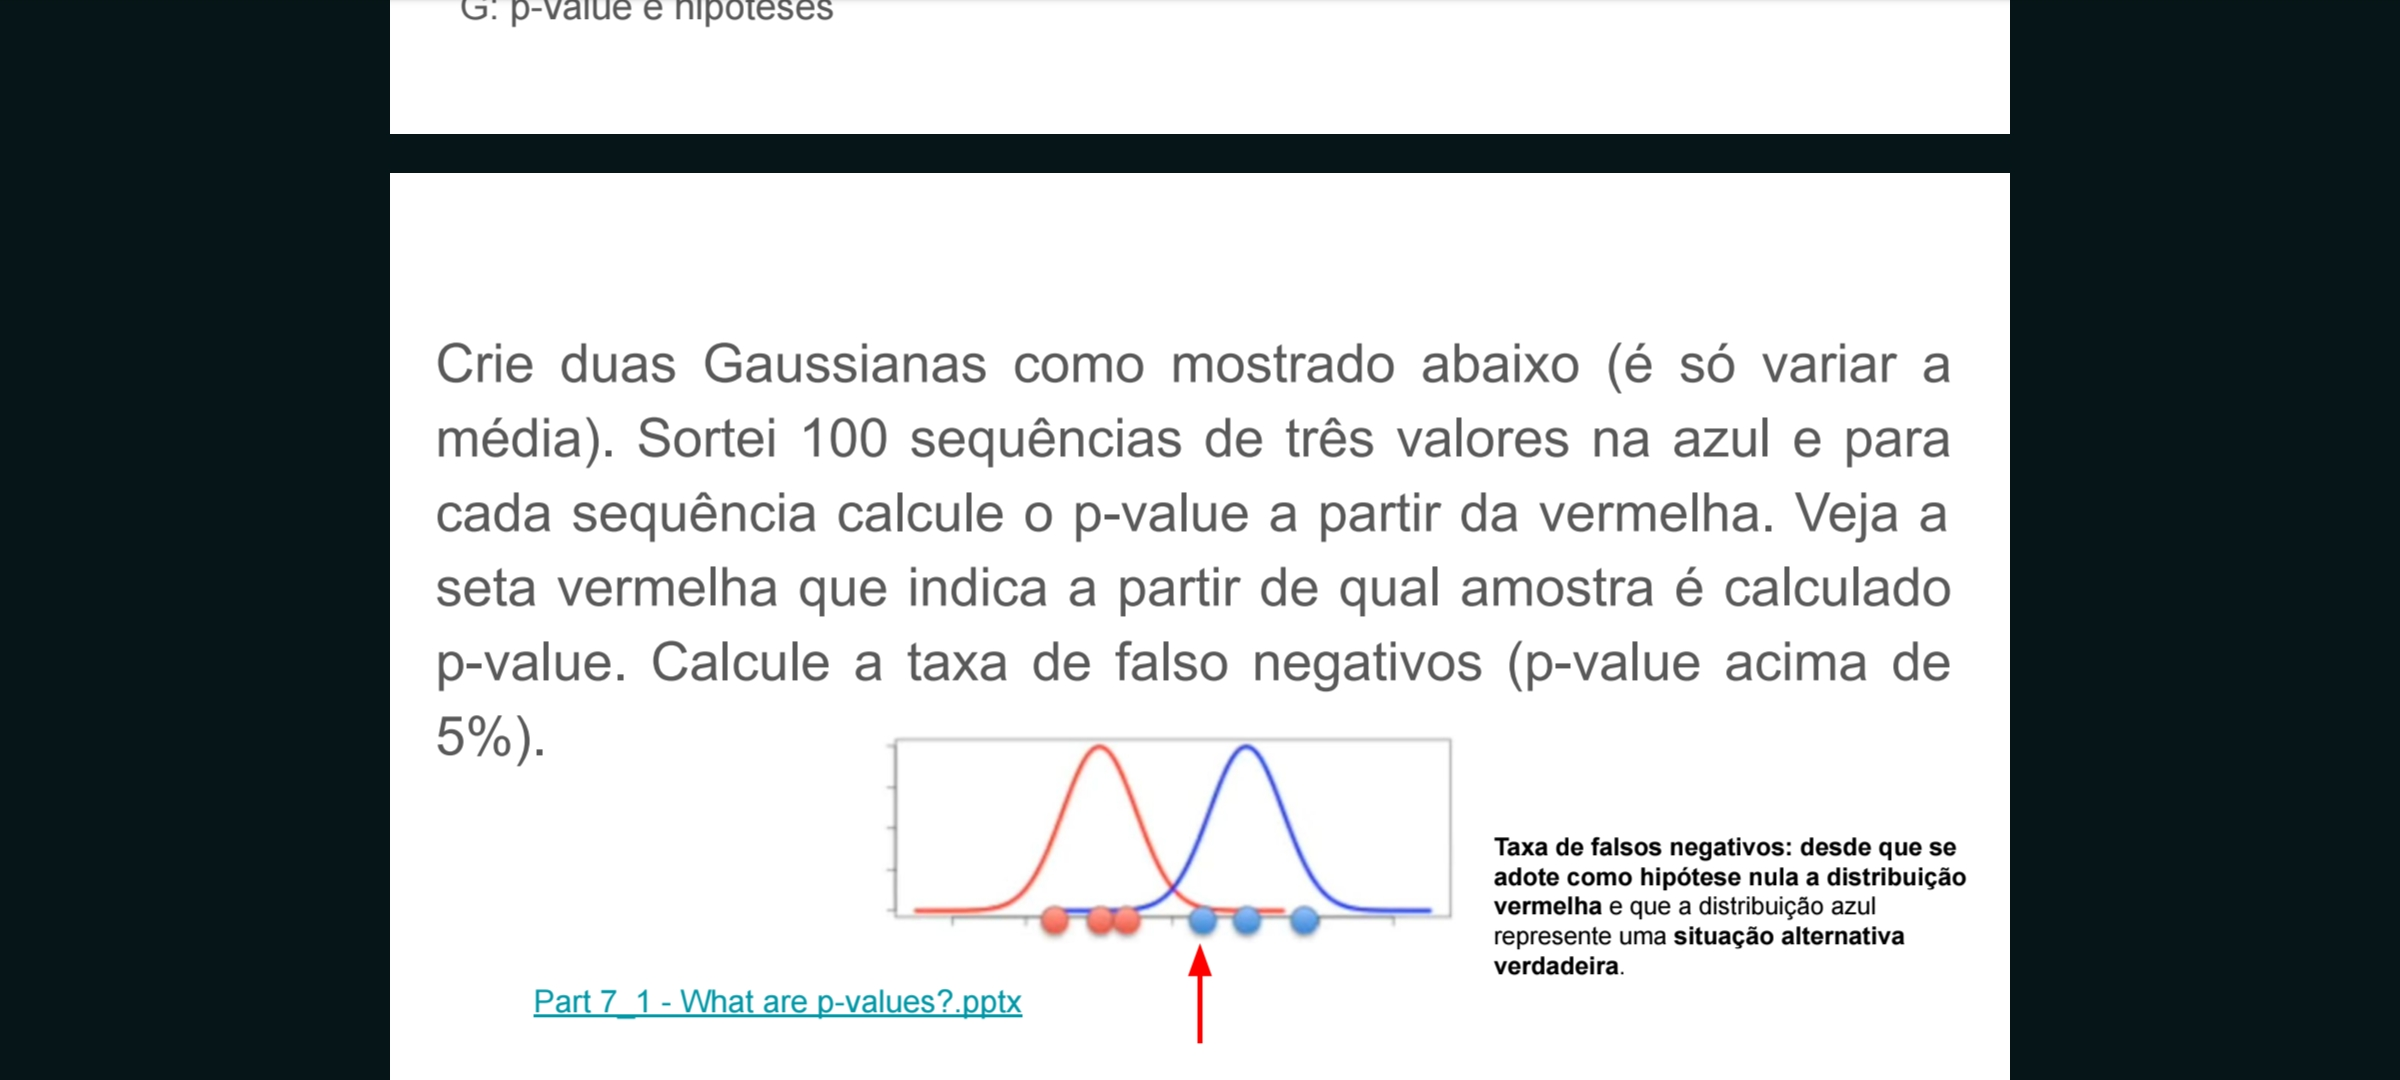

## Simulação das Duas Gaussianas, Cálculo dos P-values e Taxa de Falsos Negativos

--- Resultados da Simulação ---
Total de sequências testadas: 100
Falsos Negativos (p-value > 0.05): 96
Taxa de Falsos Negativos (Erro Tipo II): 96.00%


<>:67: SyntaxWarning: invalid escape sequence '\m'
<>:74: SyntaxWarning: invalid escape sequence '\m'
<>:67: SyntaxWarning: invalid escape sequence '\m'
<>:74: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3422/3104266355.py:67: SyntaxWarning: invalid escape sequence '\m'
  label=f'Ref. Vermelha ($\mu$={media_vermelha})',
/tmp/ipykernel_3422/3104266355.py:74: SyntaxWarning: invalid escape sequence '\m'
  label=f'Amostra Azul ($\mu$={media_azul})',


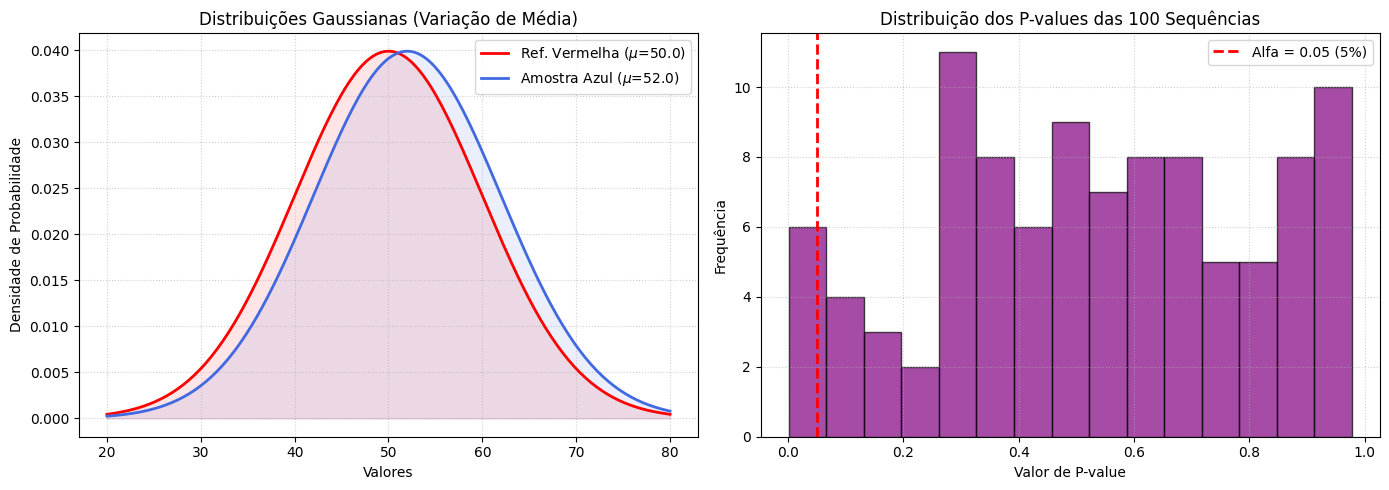

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Configurações iniciais
np.random.seed(42)
num_amostras = 100
tamanho_sequencia = 3
significance_level = 0.05

# 1. Definindo as duas Gaussianas (variando a média)
# Distribuição Azul (população real de onde tiramos as amostras)
media_azul = 52.0
desvio_padrao = 10.0

# Distribuição Vermelha (população de referência / H0)
media_vermelha = 50.0

falsos_negativos = 0
p_values = []

# 2. Sortear 100 sequências de três valores na azul e calcular o p-value com base na vermelha
for _ in range(num_amostras):
  # Sorteia 3 valores da distribuição azul
  sequencia_azul = np.random.normal(media_azul, desvio_padrao, tamanho_sequencia)

  # Média da sequência amostrada
  media_amostra = np.mean(sequencia_azul)

  # Erro padrão da média para n=3
  erro_padrao = desvio_padrao / np.sqrt(tamanho_sequencia)

  # Calcula o p-value (teste t ou z com base na distribuição vermelha)
  # Testando se a média da amostra difere da média vermelha
  t_stat = (media_amostra - media_vermelha) / erro_padrao
  p_value = 2 * (1 - stats.norm.cdf(abs(t_stat)))  # Bicaudal

  p_values.append(p_value)

  # Conta falso negativo: p-value > 5% (não rejeita H0, mas na verdade a média azul é diferente!)
  if p_value > significance_level:
    falsos_negativos += 1

taxa_falsos_negativos = falsos_negativos / num_amostras

print(f'--- Resultados da Simulação ---')
print(f'Total de sequências testadas: {num_amostras}')
print(f'Falsos Negativos (p-value > 0.05): {falsos_negativos}')
print(
    'Taxa de Falsos Negativos (Erro Tipo II):'
    f' {taxa_falsos_negativos * 100:.2f}%'
)

# 3. Visualização Gráfica das Duas Gaussianas e dos P-values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: As Duas Gaussianas
x = np.linspace(20, 80, 200)
y_vermelha = stats.norm.pdf(x, media_vermelha, desvio_padrao)
y_azul = stats.norm.pdf(x, media_azul, desvio_padrao)

axes[0].plot(
    x,
    y_vermelha,
    color='red',
    linewidth=2,
    label=f'Ref. Vermelha ($\mu$={media_vermelha})',
)
axes[0].plot(
    x,
    y_azul,
    color='royalblue',
    linewidth=2,
    label=f'Amostra Azul ($\mu$={media_azul})',
)
axes[0].fill_between(x, y_vermelha, color='red', alpha=0.1)
axes[0].fill_between(x, y_azul, color='royalblue', alpha=0.1)
axes[0].set_title('Distribuições Gaussianas (Variação de Média)')
axes[0].set_xlabel('Valores')
axes[0].set_ylabel('Densidade de Probabilidade')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Gráfico 2: Distribuição dos P-values obtidos
axes[1].hist(
    p_values, bins=15, color='purple', edgecolor='black', alpha=0.7
)
axes[1].axvline(
    significance_level,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Alfa = {significance_level} (5%)',
)
axes[1].set_title('Distribuição dos P-values das 100 Sequências')
axes[1].set_xlabel('Valor de P-value')
axes[1].set_ylabel('Frequência')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()